# 4. Calendario y estacionalidad

Los perfiles horarios y semanales permiten estudiar ciclos recurrentes y diferencias entre días laborales, festivos y fines de semana.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/panel_horario.parquet').exists())
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
panel = pq.read_table(ROOT/'data/processed/panel_horario.parquet', filters=[('inicio','<',pd.Timestamp('2022-01-01',tz='America/Bogota'))]).to_pandas()
assert panel.index.max() < pd.Timestamp('2022-01-01',tz='America/Bogota')
assert panel.index.is_monotonic_increasing and panel.index.is_unique
y = panel['y_demanda_real_kwh']
gwh = y / 1e6
registro = json.loads((ROOT/'data/processed/feature_registry.json').read_text(encoding='utf-8'))


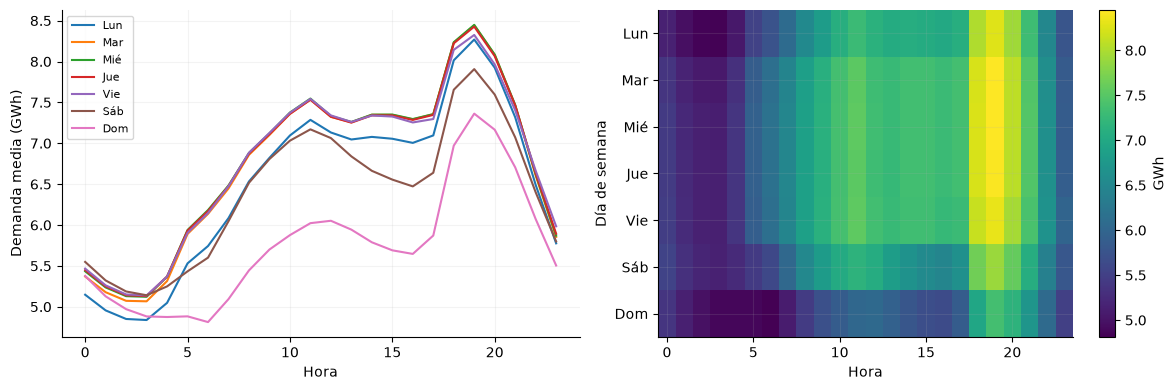

In [2]:
perfil=gwh.groupby([panel.index.day_of_week,panel.index.hour]).mean().unstack(0); pico=int(gwh.groupby(panel.index.hour).mean().idxmax()); valle=int(gwh.groupby(panel.index.hour).mean().idxmin()); fig,axes=plt.subplots(1,2,figsize=(12,4)); perfil.plot(ax=axes[0]); axes[0].set(xlabel='Hora',ylabel='Demanda media (GWh)'); axes[0].legend(['Lun','Mar','Mié','Jue','Vie','Sáb','Dom'],fontsize=8); imagen=axes[1].imshow(perfil.T,aspect='auto',cmap='viridis'); axes[1].set(xlabel='Hora',ylabel='Día de semana',yticks=range(7),yticklabels=['Lun','Mar','Mié','Jue','Vie','Sáb','Dom']); fig.colorbar(imagen,ax=axes[1],label='GWh'); fig.tight_layout(); display(fig); plt.close(fig)

El perfil agregado alcanza su máximo a las 19:00 y su mínimo a las 03:00. La matriz muestra cómo varía el ciclo diario entre días de semana; los promedios mezclan niveles de distintos años y no representan efectos causales del calendario.

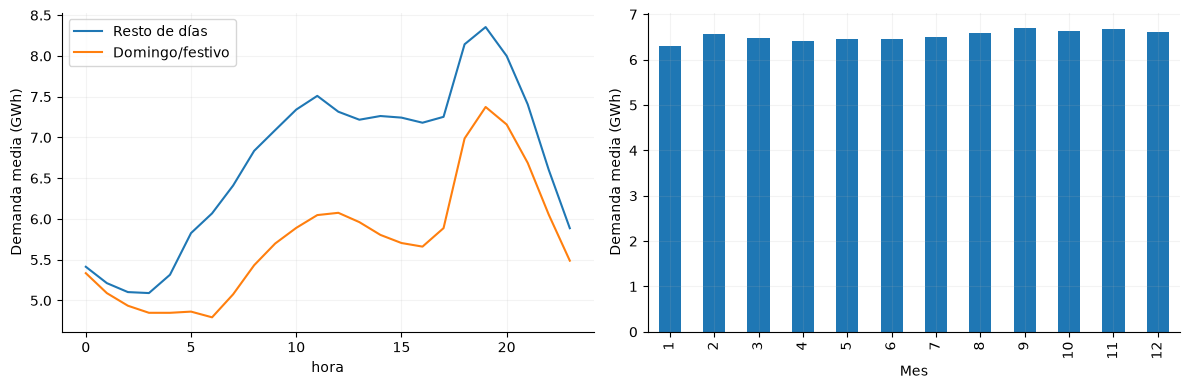

In [3]:
laboral=gwh[panel.cal_es_no_laboral==0].mean(); no_laboral=gwh[panel.cal_es_no_laboral==1].mean(); diferencia=100*(no_laboral/laboral-1); fig,axes=plt.subplots(1,2,figsize=(12,4)); pd.DataFrame({'GWh':gwh,'hora':panel.index.hour,'no_laboral':panel.cal_es_no_laboral}).groupby(['hora','no_laboral']).GWh.mean().unstack().plot(ax=axes[0]); axes[0].set_ylabel('Demanda media (GWh)'); gwh.groupby(panel.index.month).mean().plot.bar(ax=axes[1]); axes[1].set(xlabel='Mes',ylabel='Demanda media (GWh)'); axes[0].legend(['Resto de días','Domingo/festivo']); fig.tight_layout(); display(fig); plt.close(fig)
reduccion_no_laboral=-diferencia


La demanda media de domingos y festivos es un 14.5 % inferior a la del resto de días. El ciclo mensual y el intradiario aconsejan conservar calendario del horizonte; su asociación puede variar entre años.

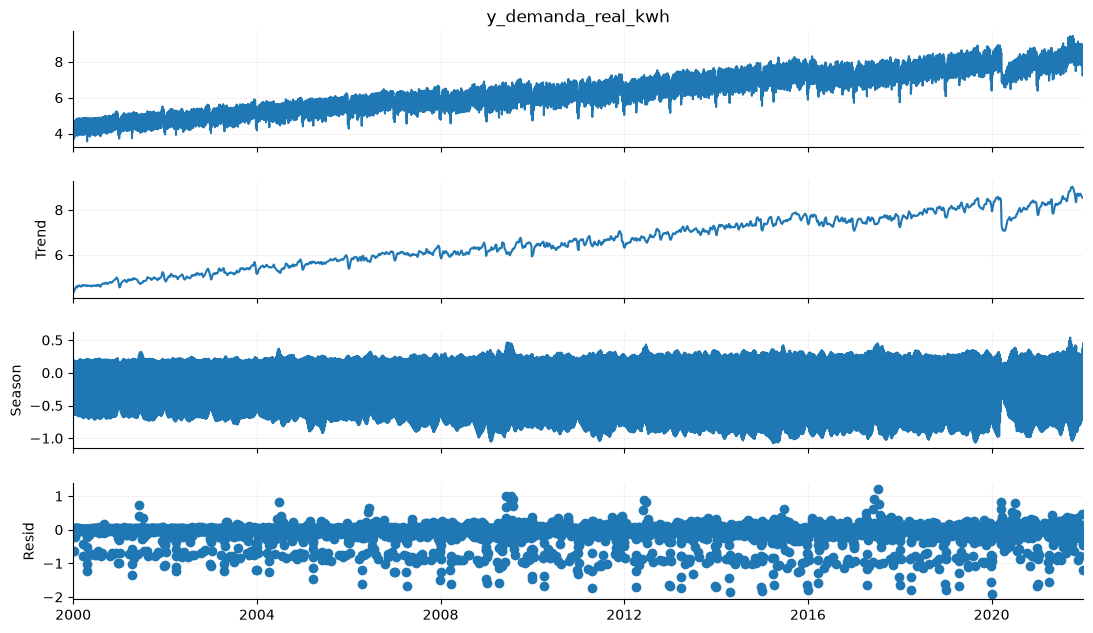

In [4]:
from statsmodels.tsa.seasonal import STL
diaria=gwh.resample('D').mean(); stl=STL(diaria,period=7,robust=True).fit(); fig=stl.plot(); fig.set_size_inches(11,7); display(fig); plt.close(fig); amplitud=float(stl.seasonal.quantile(.95)-stl.seasonal.quantile(.05)); residuo=float(stl.resid.std())

La componente semanal de la demanda diaria presenta un rango p5–p95 de 1.19 GWh, con DE residual 0.23. La tendencia recoge variaciones lentas; el residuo conserva episodios que el ciclo semanal no representa. Esta descomposición es retrospectiva y no se utiliza como entrada del horizonte.

La categoría «no laboral» comprende domingos y festivos. Los sábados no festivos se distinguen mediante cal_tipo_dia = 1; la comparación binaria no equivale a lunes–viernes frente a todo el fin de semana.

**Decisión.** Incluir hora, día de semana y festivos conocidos de los próximos 24 intervalos.

**Impacto.** Representa ciclos sin consultar covariables observadas del futuro.

**Riesgo.** Promedios globales pueden ocultar cambios estacionales y estructurales.